In [1]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 
  
# metadata 
print(wine_quality.metadata) 
  
# variable information 
print(wine_quality.variables) 


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [3]:
X = wine_quality.data.features   # the 11 chemical features
y = wine_quality.data.targets    # quality score

df = pd.concat([X, y], axis=1)
df.to_csv("../winequality.csv", index=False)

print(df.shape)
df.head()

(6497, 12)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
print(df.isna().sum().sum(), "missing values")
df.describe().round(2)

0 missing values


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00
mean,7.22,0.34,0.32,5.44,0.06,30.53,115.74,0.99,3.22,0.53,10.49,5.82
std,1.30,0.16,0.15,4.76,0.04,17.75,56.52,0.00,0.16,0.15,1.19,0.87
min,3.80,0.08,0.00,0.60,0.01,1.00,6.00,0.99,2.72,0.22,8.00,3.00
25%,6.40,0.23,0.25,1.80,0.04,17.00,77.00,0.99,3.11,0.43,9.50,5.00
50%,7.00,0.29,0.31,3.00,0.05,29.00,118.00,0.99,3.21,0.51,10.30,6.00
75%,7.70,0.40,0.39,8.10,0.06,41.00,156.00,1.00,3.32,0.60,11.30,6.00
max,15.90,1.58,1.66,65.80,0.61,289.00,440.00,1.04,4.01,2.00,14.90,9.00


In [5]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)

Duplicate rows: 1179
After removing duplicates: (5318, 12)


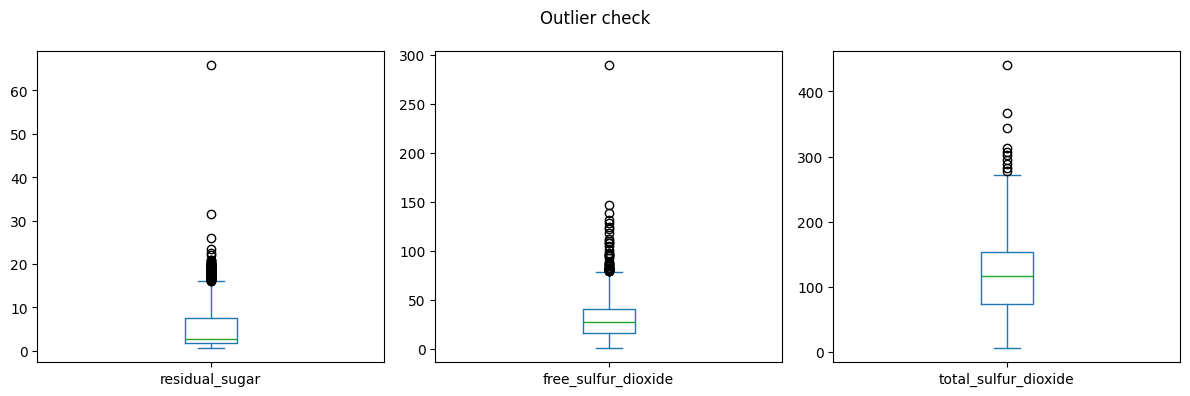

In [6]:
df[["residual_sugar", "free_sulfur_dioxide", "total_sulfur_dioxide"]].plot(
    kind="box", subplots=True, layout=(1, 3), figsize=(12, 4), title="Outlier check")
plt.tight_layout()
plt.show()

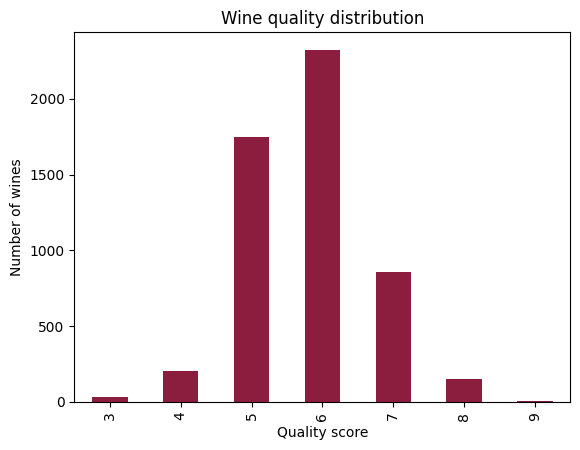

In [7]:
df["quality"].value_counts().sort_index().plot(kind="bar", color="#8b1e3f",
                                                title="Wine quality distribution")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.show()

In [8]:
df.corr()["quality"].drop("quality").sort_values(key=abs, ascending=False).round(3)

alcohol                 0.469
density                -0.326
volatile_acidity       -0.265
chlorides              -0.202
citric_acid             0.098
fixed_acidity          -0.080
residual_sugar         -0.057
free_sulfur_dioxide     0.054
total_sulfur_dioxide   -0.050
sulphates               0.042
pH                      0.040
Name: quality, dtype: float64

In [9]:
X = df.drop(columns="quality").values
y = df["quality"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=29, stratify=y
)
print(X_train.shape, X_test.shape)

(3988, 11) (1330, 11)


In [10]:
def evaluate(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": round(mean_absolute_error(y_true, y_pred), 3),             # average points off
        "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 3),    # big misses
        "R2": round(r2_score(y_true, y_pred), 3),                         # share of variation
        "exact (rounded)": round(np.mean(np.round(y_pred) == y_true), 3), # rounded prediction
        "within 1 point": round(np.mean(np.abs(y_pred - y_true) <= 1), 3),
    }

In [11]:
models = {
    "Baseline (always mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestRegressor(random_state=29)),
    "Gradient Boosting": make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=29)),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append(evaluate(name, y_test, model.predict(X_test)))

pd.DataFrame(results).sort_values("RMSE")

,model,MAE,RMSE,R2,exact (rounded),within 1 point
3,Random Forest,0.534,0.688,0.385,0.575,0.861
4,Gradient Boosting,0.540,0.691,0.380,0.581,0.862
2,KNN,0.555,0.710,0.345,0.551,0.859
1,Linear Regression,0.566,0.723,0.322,0.529,0.852
0,Baseline (always mean),0.694,0.878,-0.000,0.437,0.766


In [12]:
best_model = models["Gradient Boosting"]
feature_names = df.drop(columns="quality").columns
importances = best_model.named_steps["gradientboostingregressor"].feature_importances_

pd.Series(importances, index=feature_names).sort_values(ascending=False).round(3)

alcohol                 0.460
volatile_acidity        0.147
free_sulfur_dioxide     0.111
sulphates               0.061
total_sulfur_dioxide    0.048
residual_sugar          0.035
chlorides               0.035
citric_acid             0.031
pH                      0.030
fixed_acidity           0.027
density                 0.016
dtype: float64

In [13]:
import pickle

with open("../model.pkl", "wb") as f:
    pickle.dump(best_model, f)

import os
print("Saved model.pkl,", round(os.path.getsize("../model.pkl") / 1024, 1), "KB")

Saved model.pkl, 132.2 KB


In [14]:
loaded = pickle.load(open("../model.pkl", "rb"))

sample = X_test[0].reshape(1, -1)
pred = loaded.predict(sample)[0]
print("Input:", dict(zip(feature_names, X_test[0])))
print(f"Predicted quality: {pred:.2f} (rounded: {round(pred)})")
print("Actual quality:", y_test[0])

Input: {'fixed_acidity': np.float64(6.5), 'volatile_acidity': np.float64(0.28), 'citric_acid': np.float64(0.29), 'residual_sugar': np.float64(2.7), 'chlorides': np.float64(0.038), 'free_sulfur_dioxide': np.float64(26.0), 'total_sulfur_dioxide': np.float64(107.0), 'density': np.float64(0.9912), 'pH': np.float64(3.32), 'sulphates': np.float64(0.41), 'alcohol': np.float64(11.6)}
Predicted quality: 6.44 (rounded: 6)
Actual quality: 7
